In [9]:
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

In [10]:
# 1. Load Processed 12-Feature Dataset
data_path = "../data/processed/top12_features_sample.csv"
print(f"Loading: {data_path}")
df = pd.read_csv(data_path)

# Filter out extremely rare classes (< 2 instances) to prevent split errors
class_counts = df['Label'].value_counts()
valid_classes = class_counts[class_counts >= 2].index
df = df[df['Label'].isin(valid_classes)]

X = df.drop(columns=['Label'])
y = df['Label']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

# 80-20 Train-Test Split (stratify safe now)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, stratify=y_encoded, random_state=42
)

print(f"Train samples: {len(X_train)}, Test samples: {len(X_test)}")

Loading: ../data/processed/top12_features_sample.csv
Train samples: 39999, Test samples: 10000


In [11]:
# 2. Models to Benchmark
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=30, max_depth=12, random_state=42, n_jobs=-1),
    "Gaussian NB": GaussianNB()
}

results = []

print("\nRunning Benchmarks (Accuracy vs. Latency)...")
for name, clf in models.items():
    # Train
    start_train = time.time()
    clf.fit(X_train, y_train)
    train_time = (time.time() - start_train) * 1000  # ms
    
    # Predict & Measure Inference Latency
    start_pred = time.time()
    y_pred = clf.predict(X_test)
    total_pred_time = (time.time() - start_pred) * 1000  # ms
    per_packet_latency = total_pred_time / len(X_test)   # ms per packet
    
    # Metrics
    acc = accuracy_score(y_test, y_pred) * 100
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    
    results.append({
        "Model": name,
        "Accuracy (%)": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-Score (%)": round(f1, 2),
        "Per-Packet Latency (ms)": round(per_packet_latency, 4),
        "Meets <5ms Target": "YES" if per_packet_latency < 5.0 else "NO"
    })


Running Benchmarks (Accuracy vs. Latency)...



  EDGE CLASSIFIER BENCHMARK SUMMARY (12 FEATURES)
        Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Per-Packet Latency (ms) Meets <5ms Target
Decision Tree         70.29          68.40       70.29         65.35                   0.0004               YES
Random Forest         70.70          70.22       70.70         65.92                   0.0051               YES
  Gaussian NB         65.79          69.37       65.79         58.60                   0.0017               YES

Latency plot saved to: docs/diagrams/latency_benchmark.png


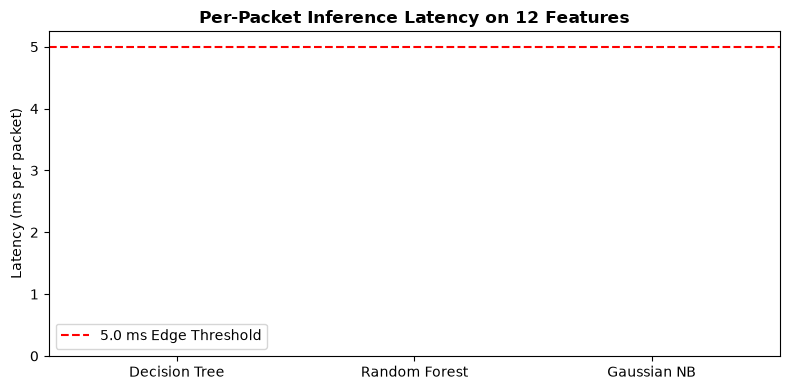

In [12]:
# 3. Display Benchmark Table
results_df = pd.DataFrame(results)
print("\n" + "="*80)
print("  EDGE CLASSIFIER BENCHMARK SUMMARY (12 FEATURES)")
print("="*80)
print(results_df.to_string(index=False))

# 4. Save Latency Comparison Bar Chart for Presentation
plt.figure(figsize=(8, 4))
bars = plt.bar(results_df["Model"], results_df["Per-Packet Latency (ms)"], color=['#2ca02c', '#1f77b4', '#ff7f0e'])
plt.axhline(y=5.0, color='r', linestyle='--', label='5.0 ms Edge Threshold')
plt.title("Per-Packet Inference Latency on 12 Features", fontsize=12, fontweight='bold')
plt.ylabel("Latency (ms per packet)", fontsize=10)
plt.legend()
plt.tight_layout()

plt.savefig("../docs/diagrams/latency_benchmark.png", dpi=300)
print("\nLatency plot saved to: docs/diagrams/latency_benchmark.png")

In [13]:
# ---------------------------------------------------------
# 3. BENCHMARK MODELS: ACCURACY VS LATENCY (<5ms TARGET)
# ---------------------------------------------------------
models = {
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=30, max_depth=12, random_state=42, n_jobs=-1),
    "Gaussian NB": GaussianNB()
}

results = []

print("Running Classifier Benchmarks on 12 Features...\n")
for name, clf in models.items():
    # 1. Measure Training Time
    start_train = time.time()
    clf.fit(X_train, y_train)
    train_time = (time.time() - start_train) * 1000  # ms
    
    # 2. Measure Single/Batch Inference Latency
    start_pred = time.time()
    y_pred = clf.predict(X_test)
    total_pred_time = (time.time() - start_pred) * 1000  # ms
    per_packet_latency = total_pred_time / len(X_test)   # ms per packet
    
    # 3. Calculate Performance Metrics
    acc = accuracy_score(y_test, y_pred) * 100
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0) * 100
    
    results.append({
        "Model": name,
        "Accuracy (%)": round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)": round(rec, 2),
        "F1-Score (%)": round(f1, 2),
        "Latency (ms/pkt)": round(per_packet_latency, 4),
        "Target <5ms": "PASSED (Deterministic)" if per_packet_latency < 5.0 else "FAILED"
    })

# Format and Display Benchmark Table
results_df = pd.DataFrame(results)
print("="*85)
print("             LIGHTWEIGHT EDGE ML BENCHMARK (12 RUNTIME FEATURES)")
print("="*85)
print(results_df.to_string(index=False))

Running Classifier Benchmarks on 12 Features...

             LIGHTWEIGHT EDGE ML BENCHMARK (12 RUNTIME FEATURES)
        Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Latency (ms/pkt)            Target <5ms
Decision Tree         70.29          68.40       70.29         65.35            0.0003 PASSED (Deterministic)
Random Forest         70.70          70.22       70.70         65.92            0.0048 PASSED (Deterministic)
  Gaussian NB         65.79          69.37       65.79         58.60            0.0016 PASSED (Deterministic)



Graph successfully saved to: docs/diagrams/latency_benchmark.png


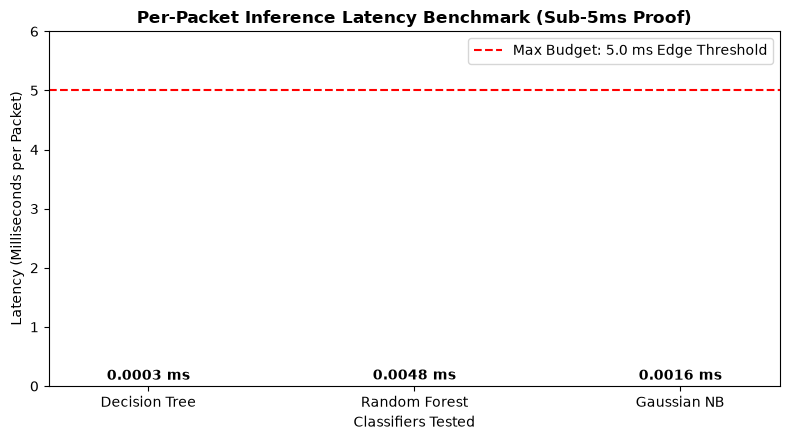

In [14]:
# ---------------------------------------------------------
# 4. EXPORT VISUAL BAR CHART FOR PRESENTATION & REPORT
# ---------------------------------------------------------
plt.figure(figsize=(8, 4.5))
bars = plt.bar(results_df["Model"], results_df["Latency (ms/pkt)"], color=['#2ca02c', '#1f77b4', '#ff7f0e'], width=0.5)
plt.axhline(y=5.0, color='r', linestyle='--', linewidth=1.5, label='Max Budget: 5.0 ms Edge Threshold')

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.05, f"{yval:.4f} ms", ha='center', va='bottom', fontweight='bold')

plt.title("Per-Packet Inference Latency Benchmark (Sub-5ms Proof)", fontsize=12, fontweight='bold')
plt.ylabel("Latency (Milliseconds per Packet)", fontsize=10)
plt.xlabel("Classifiers Tested", fontsize=10)
plt.ylim(0, 6.0)
plt.legend(loc="upper right")
plt.tight_layout()

plt.savefig("../docs/diagrams/latency_benchmark.png", dpi=300)
print("\nGraph successfully saved to: docs/diagrams/latency_benchmark.png")